In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow import keras

from aeroguard.autoencodeurs import standardiser
from aeroguard.donnees_ml import preparer_xy
from aeroguard.gan import generer
from aeroguard.qualite_synthetique import (auc_separabilite, bilan_fidelite, mesurer_memorisation,
                                           resume_fidelite, score_classifieur)

DOSSIER = "/content/drive/MyDrive/aeroguard"
FAMILLE_CIBLE = "fan"

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
X_train, y_train = preparer_xy(vols, "train")
X_val, y_val = preparer_xy(vols, "val")
medianes = X_train.median()
famille_train = vols.loc[X_train.index, "famille"].astype(str).to_numpy()
famille_val = vols.loc[X_val.index, "famille"].astype(str).to_numpy()
y_tr, y_va = np.asarray(y_train), np.asarray(y_val)

stats = np.load(f"{DOSSIER}/models/gan_fan_v6_stats.npz", allow_pickle=True)
moyennes, ecarts = stats["moyennes"], stats["ecarts"]
colonnes = [str(c) for c in stats["colonnes"]]
assert colonnes == list(X_train.columns), "Les colonnes ne correspondent pas à celles de la 6.2 !"


def preparer(X):
    """Imputation (médianes du train) + standardisation identique à celle du GAN."""
    return standardiser(X.fillna(medianes).to_numpy(dtype="float64"), moyennes, ecarts).astype("float32")


fan_tr, fan_va = famille_train == FAMILLE_CIBLE, famille_val == FAMILLE_CIBLE
X_reel = preparer(X_train[fan_tr & (y_tr == 1)])        # ce que le GAN a appris
X_sains_fan = preparer(X_train[fan_tr & (y_tr == 0)])   # vrais vols sains, pour le TSTR
X_reference = preparer(X_val[fan_va & (y_va == 1)])     # vols usés fan JAMAIS vus par le GAN
X_test_fan = preparer(X_val[fan_va])                    # test du TSTR : vrais vols uniquement
y_test_fan = y_va[fan_va]

print(f"Train fan : {len(X_reel)} usés, {len(X_sains_fan)} sains")
print(f"Validation fan : {len(X_test_fan)} vols ({int(y_test_fan.sum())} usés), "
      f"{vols.loc[X_val.index[fan_va], 'moteur'].nunique()} moteur(s)")

Mounted at /content/drive
Train fan : 340 usés, 89 sains
Validation fan : 83 vols (67 usés), 1 moteur(s)


In [3]:
gen_A = keras.models.load_model(f"{DOSSIER}/models/gan_fan_v6_generateur.keras")
gen_D = keras.models.load_model(f"{DOSSIER}/models/gan_fan_v6_stable_generateur.keras")

n = len(X_reel)
rng = np.random.default_rng(0)
candidats = {
    "A_gan_6.2": generer(gen_A, n, graine=0),
    "D_gan_lissage_6.3": generer(gen_D, n, graine=0),
    "base_gaussienne": rng.multivariate_normal(X_reel.mean(axis=0), np.cov(X_reel, rowvar=False),
                                               size=n).astype("float32"),
    "base_copies_bruitees": (X_reel[rng.integers(0, n, n)]
                             + 0.01 * rng.standard_normal(X_reel.shape)).astype("float32"),
}
for nom, faux in candidats.items():
    print(f"{nom:22s} {faux.shape}  NaN : {int(np.isnan(faux).sum())}")

A_gan_6.2              (340, 126)  NaN : 0
D_gan_lissage_6.3      (340, 126)  NaN : 0
base_gaussienne        (340, 126)  NaN : 0
base_copies_bruitees   (340, 126)  NaN : 0


In [4]:
lignes, bilans = [], {}

# Ligne de référence : un AUTRE vrai moteur fan (validation) comparé au train
bilans["vrais_val_reference"] = bilan_fidelite(X_reel, X_reference, colonnes)
lignes.append({"candidat": "vrais_val_reference", **resume_fidelite(bilans["vrais_val_reference"]),
               "auc_separabilite": auc_separabilite(X_reel, X_reference)})

for nom, faux in candidats.items():
    bilans[nom] = bilan_fidelite(X_reel, faux, colonnes)
    lignes.append({"candidat": nom, **resume_fidelite(bilans[nom]),
                   "auc_separabilite": auc_separabilite(X_reel, faux),
                   **mesurer_memorisation(X_reel, faux, X_reference)})

evaluation = pd.DataFrame(lignes).set_index("candidat")
evaluation.round(3)

,ks_median,part_ks_eleve,ecart_moyennes_median,rapport_iqr_median,auc_separabilite,dcr_faux_median,dcr_reference_median,rapport_dcr,part_quasi_copies
candidat,,,,,,,,,
vrais_val_reference,0.193,0.429,0.491,1.189,0.795,NaN,NaN,NaN,NaN
A_gan_6.2,0.147,0.222,0.124,1.068,1.000,6.143,4.866,1.263,0.0
D_gan_lissage_6.3,0.151,0.317,0.116,1.067,1.000,5.919,4.866,1.216,0.0
base_gaussienne,0.191,0.397,0.060,1.693,0.423,7.943,4.866,1.632,0.0
base_copies_bruitees,0.053,0.000,0.067,1.044,0.408,0.111,4.866,0.023,1.0


In [5]:
def entrainer_et_tester(X_uses):
    """Usés (vrais ou faux) + vrais sains du train → test sur les vrais vols fan de la validation."""
    X_app = np.vstack([X_uses, X_sains_fan])
    y_app = np.r_[np.ones(len(X_uses)), np.zeros(len(X_sains_fan))]
    return score_classifieur(X_app, y_app, X_test_fan, y_test_fan)


trtr = entrainer_et_tester(X_reel)
print(f"TRTR (vrais usés) : PR-AUC {trtr['pr_auc']:.3f} | exactitude équilibrée {trtr['exactitude_equilibree']:.3f}")
for nom, faux in candidats.items():
    tstr = entrainer_et_tester(faux)
    evaluation.loc[nom, "tstr_pr_auc"] = tstr["pr_auc"]
    evaluation.loc[nom, "tstr_exactitude_eq"] = tstr["exactitude_equilibree"]
    evaluation.loc[nom, "tstr_sur_trtr"] = tstr["exactitude_equilibree"] / trtr["exactitude_equilibree"]

evaluation.to_csv(f"{DOSSIER}/results/64_evaluation_faux_vols.csv")
evaluation.round(3)

TRTR (vrais usés) : PR-AUC 0.985 | exactitude équilibrée 0.564


,ks_median,part_ks_eleve,ecart_moyennes_median,rapport_iqr_median,auc_separabilite,dcr_faux_median,dcr_reference_median,rapport_dcr,part_quasi_copies,tstr_pr_auc,tstr_exactitude_eq,tstr_sur_trtr
candidat,,,,,,,,,,,,
vrais_val_reference,0.193,0.429,0.491,1.189,0.795,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A_gan_6.2,0.147,0.222,0.124,1.068,1.000,6.143,4.866,1.263,0.0,0.931,0.737,1.308
D_gan_lissage_6.3,0.151,0.317,0.116,1.067,1.000,5.919,4.866,1.216,0.0,0.941,0.752,1.334
base_gaussienne,0.191,0.397,0.060,1.693,0.423,7.943,4.866,1.632,0.0,0.966,0.634,1.124
base_copies_bruitees,0.053,0.000,0.067,1.044,0.408,0.111,4.866,0.023,1.0,0.980,0.713,1.264


In [6]:
gans = evaluation.loc[["A_gan_6.2", "D_gan_lissage_6.3"]]
sans_copie = gans[gans["part_quasi_copies"] <= 0.05]
retenu = sans_copie["ks_median"].idxmin()

print(gans[["ks_median", "part_ks_eleve", "ecart_moyennes_median", "rapport_iqr_median",
            "auc_separabilite", "rapport_dcr", "part_quasi_copies", "tstr_sur_trtr"]].round(3))
print(f"\n✅ GAN retenu : {retenu}")

gauss = evaluation.loc["base_gaussienne"]
print(f"Le GAN retenu bat-il la gaussienne ? KS médian {evaluation.loc[retenu, 'ks_median']:.3f} "
      f"contre {gauss['ks_median']:.3f} ; TSTR/TRTR {evaluation.loc[retenu, 'tstr_sur_trtr']:.2f} "
      f"contre {gauss['tstr_sur_trtr']:.2f}")
print(f"Le détecteur repère-t-il les copies ? part_quasi_copies des copies bruitées : "
      f"{evaluation.loc['base_copies_bruitees', 'part_quasi_copies']:.0%}")

fichier = "gan_fan_v6_generateur.keras" if retenu == "A_gan_6.2" else "gan_fan_v6_stable_generateur.keras"
with open(f"{DOSSIER}/models/gan_fan_v6_retenu.json", "w") as f:
    json.dump({"retenu": retenu, "fichier": fichier,
               "regle": "KS médian minimal parmi les GAN sans mémorisation (part_quasi_copies <= 5 %)",
               "evaluation": {k: round(float(v), 3) for k, v in evaluation.loc[retenu].items()}}, f, indent=2)

                   ks_median  part_ks_eleve  ecart_moyennes_median  \
candidat                                                             
A_gan_6.2              0.147          0.222                  0.124   
D_gan_lissage_6.3      0.151          0.317                  0.116   

                   rapport_iqr_median  auc_separabilite  rapport_dcr  \
candidat                                                               
A_gan_6.2                       1.068               1.0        1.263   
D_gan_lissage_6.3               1.067               1.0        1.216   

                   part_quasi_copies  tstr_sur_trtr  
candidat                                             
A_gan_6.2                        0.0          1.308  
D_gan_lissage_6.3                0.0          1.334  

✅ GAN retenu : A_gan_6.2
Le GAN retenu bat-il la gaussienne ? KS médian 0.147 contre 0.191 ; TSTR/TRTR 1.31 contre 1.12
Le détecteur repère-t-il les copies ? part_quasi_copies des copies bruitées : 100%


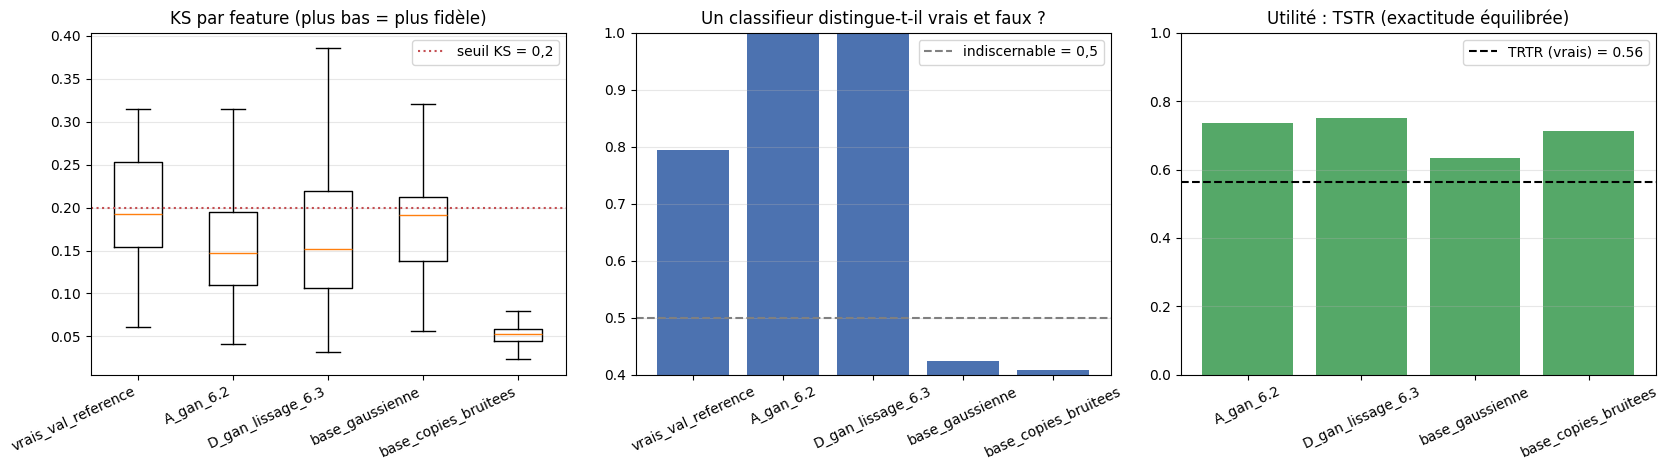

In [7]:
noms = ["vrais_val_reference", "A_gan_6.2", "D_gan_lissage_6.3", "base_gaussienne", "base_copies_bruitees"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].boxplot([bilans[nom]["ks"] for nom in noms], showfliers=False)
axes[0].set_xticks(range(1, len(noms) + 1), noms, rotation=25, ha="right")
axes[0].axhline(0.2, color="#C44E52", linestyle=":", label="seuil KS = 0,2")
axes[0].set_title("KS par feature (plus bas = plus fidèle)")
axes[0].legend()

axes[1].bar(noms, evaluation.loc[noms, "auc_separabilite"], color="#4C72B0")
axes[1].axhline(0.5, color="gray", linestyle="--", label="indiscernable = 0,5")
axes[1].set_ylim(0.4, 1.0)
axes[1].tick_params(axis="x", rotation=25)
axes[1].set_title("Un classifieur distingue-t-il vrais et faux ?")
axes[1].legend()

candidats_noms = list(candidats)
axes[2].bar(candidats_noms, evaluation.loc[candidats_noms, "tstr_exactitude_eq"], color="#55A868")
axes[2].axhline(trtr["exactitude_equilibree"], color="black", linestyle="--",
                label=f"TRTR (vrais) = {trtr['exactitude_equilibree']:.2f}")
axes[2].set_ylim(0, 1)
axes[2].tick_params(axis="x", rotation=25)
axes[2].set_title("Utilité : TSTR (exactitude équilibrée)")
axes[2].legend()

for axe in axes:
    axe.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/64_evaluation_faux_vols.png", dpi=150, bbox_inches="tight")
plt.show()

                      ks  ecart_moyennes  rapport_iqr
feature                                              
P2_std_croisiere   0.315           0.321        1.149
Ps30_max_montee    0.312           0.328        1.460
P21_mean_descente  0.303           0.258        1.167
T48_std_montee     0.303           0.386        0.905


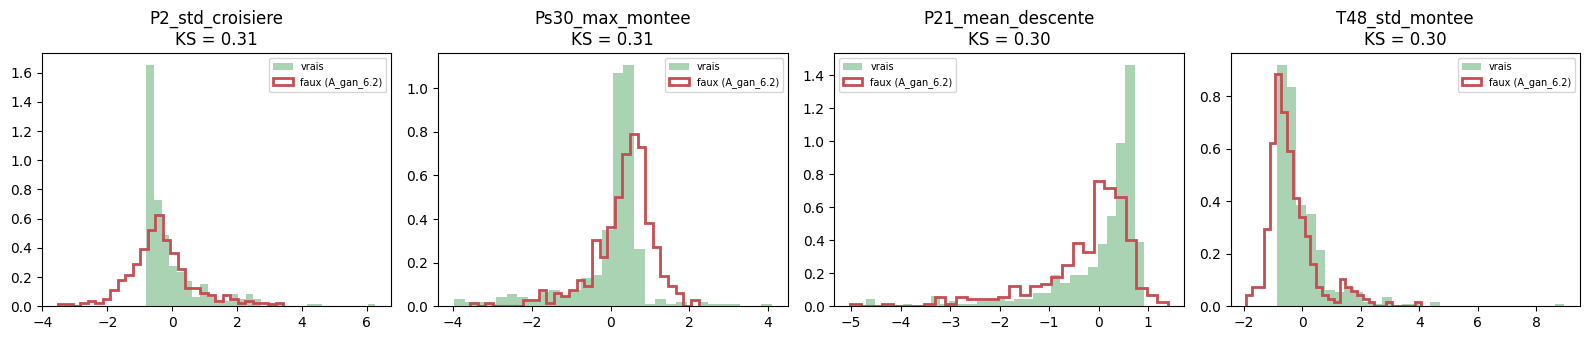

In [8]:
pires = bilans[retenu].head(4)
print(pires.round(3))

j_pires = [colonnes.index(c) for c in pires.index]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for axe, j, nom in zip(axes, j_pires, pires.index):
    axe.hist(X_reel[:, j], bins=30, density=True, alpha=0.5, label="vrais", color="#55A868")
    axe.hist(candidats[retenu][:, j], bins=30, density=True, histtype="step", linewidth=2,
             label=f"faux ({retenu})", color="#C44E52")
    axe.set_title(f"{nom}\nKS = {pires.loc[nom, 'ks']:.2f}")
    axe.legend(fontsize=7)
plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/64_pires_features.png", dpi=150, bbox_inches="tight")
plt.show()